# Confidence-Threshold Cascade Experiment

Given a trained `HierRouteNet` checkpoint, this notebook evaluates a **selective, confidence-gated prediction rule**: starting from the deepest level the model's greedy routing actually reached, accept that level's prediction if its local (conditional) softmax confidence clears a per-level threshold; otherwise back off one level toward root and check again. If even the coarsest (level 1) decision fails its threshold, the sample is reported as **unclassified** -- no forced guess.

Example (matches the spec this notebook implements): a sample routes to leaf `Daphnia` with per-level confidences `[0.95, 0.90, 0.60]` (level 1, 2, 3). With thresholds `[0.9, 0.9, 0.8]`: level 3 fails (0.60 < 0.8) -> back off to level 2: passes (0.90 >= 0.9) -> final prediction is `Cladocera` (the level-2 ancestor), not `Daphnia`.

Test data is the **held-out split of the main Hier-Zooplankton dataset** (`build_test_loader()` from `runs/scripts/eval_loaders.py` -- same `ImageDataset` construction, `hiernet_adjacency_graph` taxonomy and seeded `0.7/0.1/0.2` split as `runs/train_swin_cnn_mnr.py`, so the test indices line up with the trained checkpoints). Not `Messy_background` -- see `runs/hiernet_mnr.ipynb` for that.

**Note on transforms:** `build_test_loader()` uses a **clean `Resize + ToTensor` pipeline** (`eval_loaders.EVAL_TRANSFORMS`), not the training augmentation (flips / `RandomBackgroundNoise` / rotation). Results are therefore deterministic across reruns and directly comparable with the `Messy_background` evaluation in `hiernet_mnr.ipynb`, which uses the same pipeline. This differs slightly from the augmented "test" loader `train_swin_cnn_mnr.py` builds for its own in-training metric; pass a custom `image_transforms=` to `build_test_loader()` if you want to reproduce that.

**Note on hierarchy versioning:** the checkpoint's `TRAINING_RESULT_PATH` must have been trained against the *same* `hiernet_adjacency_graph`/`HIERNET_CLASSES` currently in `hierroute/constants.py` -- if the taxonomy has changed since that checkpoint was trained (different leaf count/structure), loading will fail or silently mismatch.

In [1]:
import os
import sys
from pathlib import Path

import torch
from dotenv import load_dotenv

project_root = Path().resolve().parent
sys.path.append(str(project_root))
sys.path.append(str(project_root / 'runs' / 'scripts'))
load_dotenv()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hierroute import HierRouteNet

from eval_loaders import build_test_loader, build_messy_loader
from hiernet_eval import (
    collect_predictions,
    split_level_confidences, plot_level_confidence_hist,
    level_roc, plot_level_roc, roc_summary_frame,
    evaluate_thresholds, settle_depth_distribution,
    threshold_grid_search, plot_threshold_grid, print_grid_search_report,
    per_class_id_outcomes, plot_id_outcome_stacked_bar, ID_OUTCOME_KEYS,
)

In [3]:
TRAINING_RESULT_PATH = str(project_root / 'training_result/mnr/swin_t_cnn_noise_08-25')  # <-- point this at any checkpoint_dir
# TRAINING_RESULT_PATH = str(project_root / 'training_result/mnr/swin_t_cnn_baseline_08-23')
# TRAINING_RESULT_PATH = str(project_root / 'training_result/mnr/efficientnet_b0_cnn_noise_08-23')

BACKBONE = 'swin_t'      # set to 'efficientnet_b0' for that checkpoint family
EXPERT_TYPE = 'cnn'

print(f'Loading from: {TRAINING_RESULT_PATH}')

Loading from: /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25


## Build the held-out test loader

`build_test_loader()` (from `runs/scripts/eval_loaders.py`) rebuilds the main Hier-Zooplankton dataset with the same `ImageDataset` args as `runs/train_swin_cnn_mnr.py` (`data_subdirectories=['IssacData']`, `Messy_background` images excluded), takes the seeded `0.7/0.1/0.2` split, and returns `(hier_dataset, messy_loader)` over the **test** indices with a clean `Resize + ToTensor` pipeline. The split is deterministic on `SEED`, so `messy_loader` covers exactly the samples the released checkpoints were held out from.

In [4]:
messy_hier_dataset, messy_loader = build_messy_loader()

[leaves_only] Kept 12314 samples | Removed 0 non-leaf samples

Total Dataset: Size = 12314 | Levels = 3
all_node_counts: {0: 12314, 1: 11922, 3: 6598, 6: 2210, 7: 1926, 8: 2462, 4: 2596, 9: 1369, 10: 556, 11: 221, 12: 216, 13: 234, 5: 2728, 14: 197, 15: 1400, 16: 615, 17: 516, 2: 392}

nodes_by_level: {0: [0], 1: [1, 2], 2: [3, 4, 5], 3: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]}


------------------------Level 0------------------------
Level: 0 | Class Name: root                 | Class Label:   0 | Type: Parent | Count:  12314 | Prop: 1.00

------------------------Level 1------------------------
Level: 1 | Class Name: Zoop-yes             | Class Label:   1 | Type: Parent | Count:  11922 | Prop: 0.97
Level: 1 | Class Name: Zoop-No              | Class Label:   2 | Type: Leaf   | Count:    392 | Prop: 0.03

------------------------Level 2------------------------
Level: 2 | Class Name: Copepoda             | Class Label:   3 | Type: Parent | Count:   6598 | Prop: 0.54
Level: 2 | Cla

## Load the checkpoint

In [5]:
model = HierRouteNet(
    hierarchy=messy_hier_dataset.hierarchy,
    label_to_id=messy_hier_dataset.label_to_ids,
    backbone=BACKBONE,
    expert_type=EXPERT_TYPE,
    checkpoint_dir=TRAINING_RESULT_PATH,
)
model.to(device)
model.eval()

Loaded checkpoint: /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25/best_model.pt


HierRouteNet(
  (shared): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=96, out_features=288, bias=True)
          (proj): Linear(in_features=96, out_features=96, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): MLP(
          (0): Linear(in_features=96, out_features=384, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=384, out_features=96, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): S

# Visualize confidence

## Greedy routing with per-level confidence

Everything below is driven by `runs/scripts/hiernet_eval.py` (shared with `runs/hiernet_mnr.ipynb` and `runs/experiment_scripts/confidence_threshold_table.py`):

- `predict_with_confidences(model, x)` -- `HierRouteNet.predict()`'s root-to-leaf greedy walk, also recording each step's local (conditional) softmax confidence (the same `weights` `HierRouteNet.forward()` uses for its path-product, not the cumulative path probability). `confidences[d]` is the confidence behind the decision that produced `path[d + 1]`; a path that terminates early (e.g. at `Zoop-No`, depth 1) has a shorter list.
- `collect_predictions(model, loader, device)` -- runs it once over `messy_loader`, returning the `(all_paths, all_confidences, all_true_leaves)` cache every cell below reuses.
- `split_level_confidences`, `level_roc`, `evaluate_thresholds`, `settle_depth_distribution`, `threshold_grid_search` -- pure-Python analyses over that cache; the model never re-runs.

## Run inference once over the test set

Caches `(path, confidences, true_leaf_id)` per sample. Every experiment below reuses this cache -- only pure-Python decision logic changes per threshold, the model never re-runs.

In [6]:
all_paths, all_confidences, all_true_leaves = collect_predictions(model, messy_loader, device)
print(f'Cached predictions for {len(all_paths)} test samples')

Cached predictions for 12314 test samples


## Confidence-threshold cascade

`thresholds[d]` gates the depth-`(d + 1)` decision. Starting from the deepest decision a sample's path actually made, back off toward root until a level clears its threshold; if even the level-1 decision fails, the sample is **unclassified** (`None`) rather than forced to a guess.

## Visualize confidence

Per-level confidence distributions from the cached greedy routing (`all_confidences`), before any threshold is applied. Two views: every test sample, and only the samples the model's own greedy (un-thresholded) prediction got wrong -- i.e. where the deepest node its routing reached (`path[-1]`) isn't the true leaf. If wrong predictions cluster at lower confidence than the overall distribution, that's exactly the signal a confidence-threshold cascade can exploit.

1273 / 12314 samples wrongly predicted by unthresholded greedy routing (10.3%)


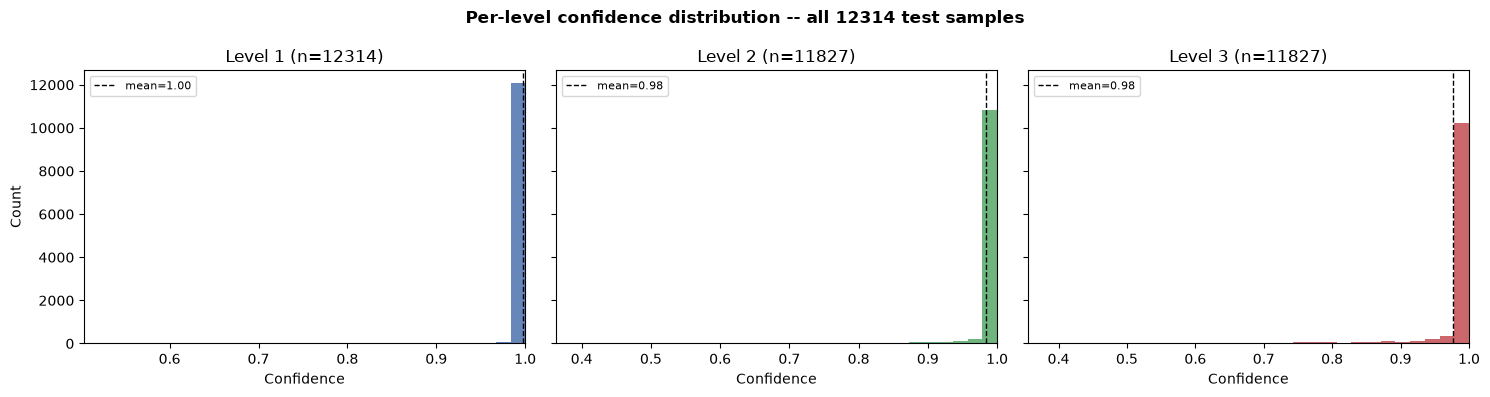

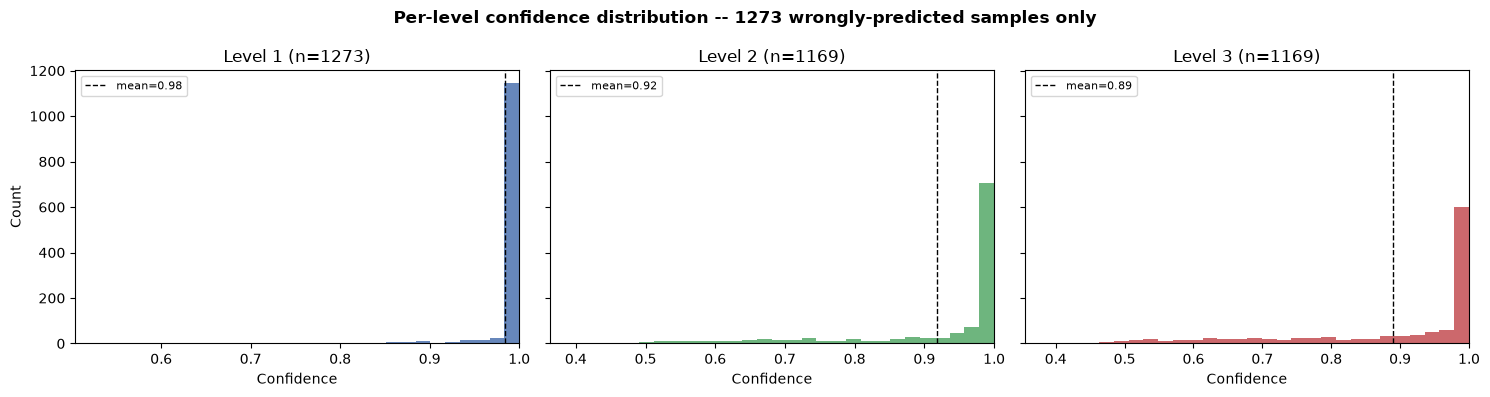

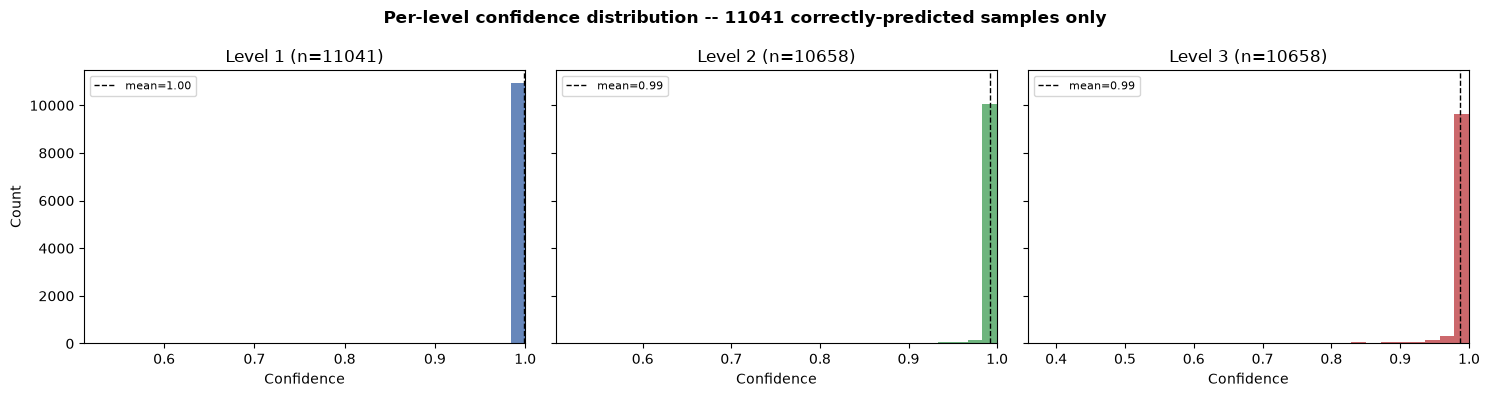

In [7]:
# Leaf-graded split: each greedy decision's confidence, bucketed by whether the sample's
# FINAL leaf prediction (path[-1]) is right. If wrong predictions sit at lower confidence
# than the overall distribution, a confidence-threshold cascade can exploit that.
level_confidences, wrong_level_confidences, correct_level_confidences, n_wrong = split_level_confidences(
    all_paths, all_confidences, all_true_leaves)

print(f'{n_wrong} / {len(all_paths)} samples wrongly predicted by unthresholded greedy routing '
      f'({n_wrong / len(all_paths):.1%})')

plot_level_confidence_hist(level_confidences,
                           f'Per-level confidence distribution -- all {len(all_paths)} test samples')
plot_level_confidence_hist(wrong_level_confidences,
                           f'Per-level confidence distribution -- {n_wrong} wrongly-predicted samples only')
plot_level_confidence_hist(correct_level_confidences,
                           f'Per-level confidence distribution -- {len(all_paths) - n_wrong} correctly-predicted samples only')
plt.show()

Level 2 here is the confidence behind the *level-2 decision* (`Zoop-yes` -> `Copepoda`/`Cladocera`/`Rotifer`), which every sample routed below `Zoop-yes` makes -- so it is populated, not empty. Only samples whose greedy path stops at the `Zoop-No` leaf (depth 1) contribute a level-1 confidence and nothing deeper.

# ROC curve

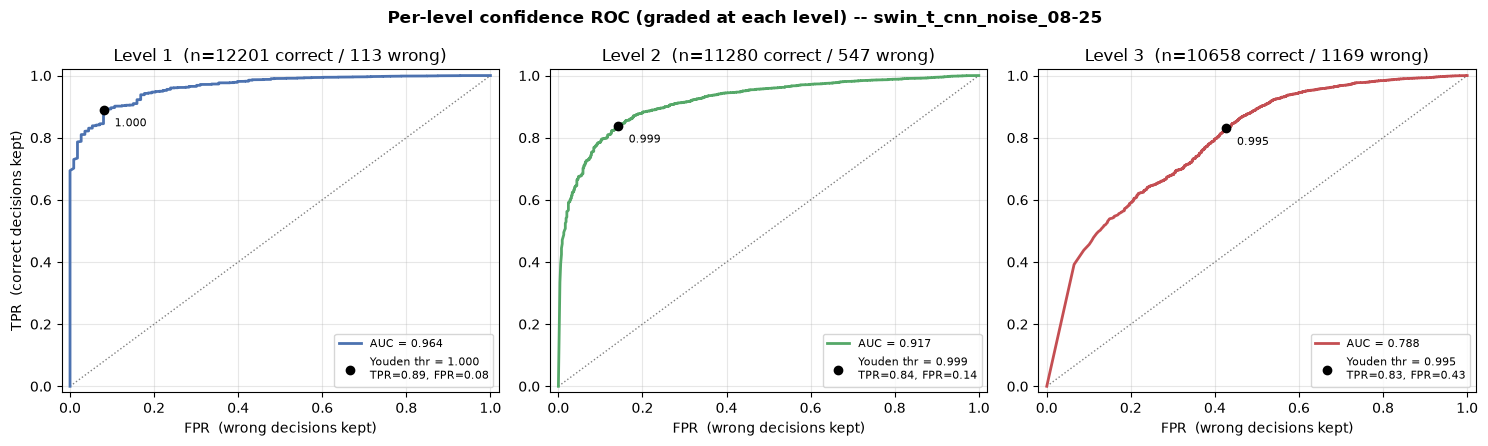

Youden-J-optimal per-level confidence thresholds (candidate cascade vector):


,level,auc,youden_threshold,tpr_at_threshold,fpr_at_threshold,n_correct,n_wrong
0,1,0.9638,0.9999,0.8903,0.0796,12201,113
1,2,0.9175,0.9992,0.8381,0.1408,11280,547
2,3,0.7875,0.9949,0.8305,0.4260,10658,1169


In [8]:
# Grade every greedy decision against the TRUE node at its OWN level -- not the leaf.
# level_roc() (runs/scripts/hiernet_eval.py): the depth-d decision produced path[d] with
# confidence confidences[d - 1]; it's "correct" iff path[d] lies on the true leaf's
# root->leaf path (the model routed into the right branch at that level).
#   level 1 -> Zoop-yes vs Zoop-No   |   level 2 -> coarse group   |   level 3 -> leaf
# Sweeping accept-if-conf >= t then traces an ROC per level (TPR = correct decisions kept,
# FPR = wrong decisions kept); the marked point maximizes Youden's J (TPR - FPR).
roc = level_roc(all_paths, all_confidences, all_true_leaves, model.hierarchy)

plot_level_roc(roc, title=f'Per-level confidence ROC (graded at each level) -- {os.path.basename(TRAINING_RESULT_PATH)}')
plt.show()

roc_summary = roc_summary_frame(roc)
print('Youden-J-optimal per-level confidence thresholds (candidate cascade vector):')
roc_summary

## Outcome classification

For a predicted node against the true leaf, and whether the cascade backed off from the deepest decision the greedy path actually reached (`predicted_depth < max_depth`) or committed to it (`predicted_depth == max_depth`):

- `correct_lowest` -- predicted the true leaf itself (only possible with no backoff -- a leaf can't sit partway along another leaf's path).
- `loosely_correct` -- backed off to a genuine ancestor of the true leaf: right branch, just coarser.
- `loosely_incorrect` -- backed off, but to a node that *isn't* an ancestor of the true leaf either: hedged, and still wrong.
- `incorrect` -- committed to the deepest decision (no backoff) and it was the wrong leaf entirely.
- `abstained` -- even the level-1 decision failed its threshold; no prediction made.

In [9]:
from functools import partial

# evaluate_thresholds(thresholds, all_paths, all_confidences, all_true_leaves, hierarchy)
# lives in hiernet_eval; bind the cache + hierarchy so the calls below stay short:
#   score([t1, t2, t3]) -> whole-test-set outcome tally (correct_lowest / loosely_correct /
#   loosely_incorrect / incorrect / abstained), see the "Outcome classification" list above.
score = partial(evaluate_thresholds,
                all_paths=all_paths, all_confidences=all_confidences,
                all_true_leaves=all_true_leaves, hierarchy=model.hierarchy)

## Try the spec's own example

In [10]:
score([0.999, 0.99, 0.95])

{'thresholds': (0.999, 0.99, 0.95),
 'n': 12314,
 'correct_lowest': '10356 (84.1%)',
 'loosely_correct': '1080 (8.8%)',
 'loosely_incorrect': '17 (0.1%)',
 'incorrect': '698 (5.7%)',
 'abstained': '163 (1.3%)',
 '_counts': {'correct_lowest': 10356,
  'loosely_correct': 1080,
  'loosely_incorrect': 17,
  'incorrect': 698,
  'abstained': 163}}

In [11]:
score([0.99, 0.95, 0.9])

{'thresholds': (0.99, 0.95, 0.9),
 'n': 12314,
 'correct_lowest': '10587 (86.0%)',
 'loosely_correct': '795 (6.5%)',
 'loosely_incorrect': '32 (0.3%)',
 'incorrect': '812 (6.6%)',
 'abstained': '88 (0.7%)',
 '_counts': {'correct_lowest': 10587,
  'loosely_correct': 795,
  'loosely_incorrect': 32,
  'incorrect': 812,
  'abstained': 88}}

## Threshold grid search: accuracy / error / abstention

`threshold_grid_search(...)` (in `hiernet_eval.py`) does the full Cartesian sweep over `t1 x t2 x t3` (8 x 11 x 20 = 1,760 combinations). Every rate is over **all n test samples** (abstentions in the denominator), so the four sum to 1:

- **`acc`** `= (correct_lowest + loosely_correct) / n` -- fraction of all samples where the cascade landed on the true leaf *or* a true ancestor (right branch, coarser).
- **`strict_acc`** `= correct_lowest / n` -- fraction that hit the exact leaf.
- **`err`** `= (loosely_incorrect + incorrect) / n` -- fraction where it committed and was wrong.
- **`abstain_pct`** `= abstained / n` -- fraction it declined to predict.

`acc` alone is maximized by barely abstaining, so the useful tradeoff is **`err` vs `abstain_pct`** (both lower is better). `print_grid_search_report` prints the highest-`acc` and lowest-`err` combos, the lowest-`err` combo's settle-depth breakdown, the top-10 by `err`, and the `(abstain % -> err)` Pareto frontier. `plot_threshold_grid` returns `(fig, frontier, best_combo)` (`best_combo` = lowest-`err` row): **Panel A** every combo as (abstain %, err %) coloured by `t3` with the frontier + min-err star; **Panel B** the error surface over `(t2, t3)` at the lowest-`err` combo's `t1`, white = accuracy contours.

Evaluated 1,760 combinations  (8 x 11 x 20)

HIGHEST OVERALL ACCURACY   (acc = (correct_lowest + loosely_correct) / n)
  thresholds [t1, t2, t3]  = [0.9, 0.995, 0.99]
  acc = 0.9448   strict_acc = 0.7817   err = 0.0510   abstain % = 0.42%

LOWEST OVERALL ERROR   (err = (loosely_incorrect + incorrect) / n)
  thresholds [t1, t2, t3]  = [0.9995, 0.995, 0.99]
  err        = 0.0470   (579 / 12314 flat-wrong)
  acc        = 0.9328   (strict 0.7799)
  abstain %  = 2.01%   (248 / 12314)
  settles at:  abstained=248   level 1=846   level 2=1431   level 3=9789

Top 10 combinations by lowest error:
    t1    t2   t3    acc strict_acc    err abstain_pct  covered
0.9995 0.995 0.99 0.9328     0.7799 0.0470       2.01%    12066
0.9990 0.995 0.99 0.9371     0.7803 0.0474       1.55%    12123
0.9995 0.990 0.99 0.9332     0.7799 0.0476       1.92%    12077
0.9990 0.990 0.99 0.9371     0.7803 0.0480       1.49%    12131
0.9995 0.980 0.99 0.9338     0.7799 0.0487       1.75%    12099
0.9900 0.995 0.99 0.9

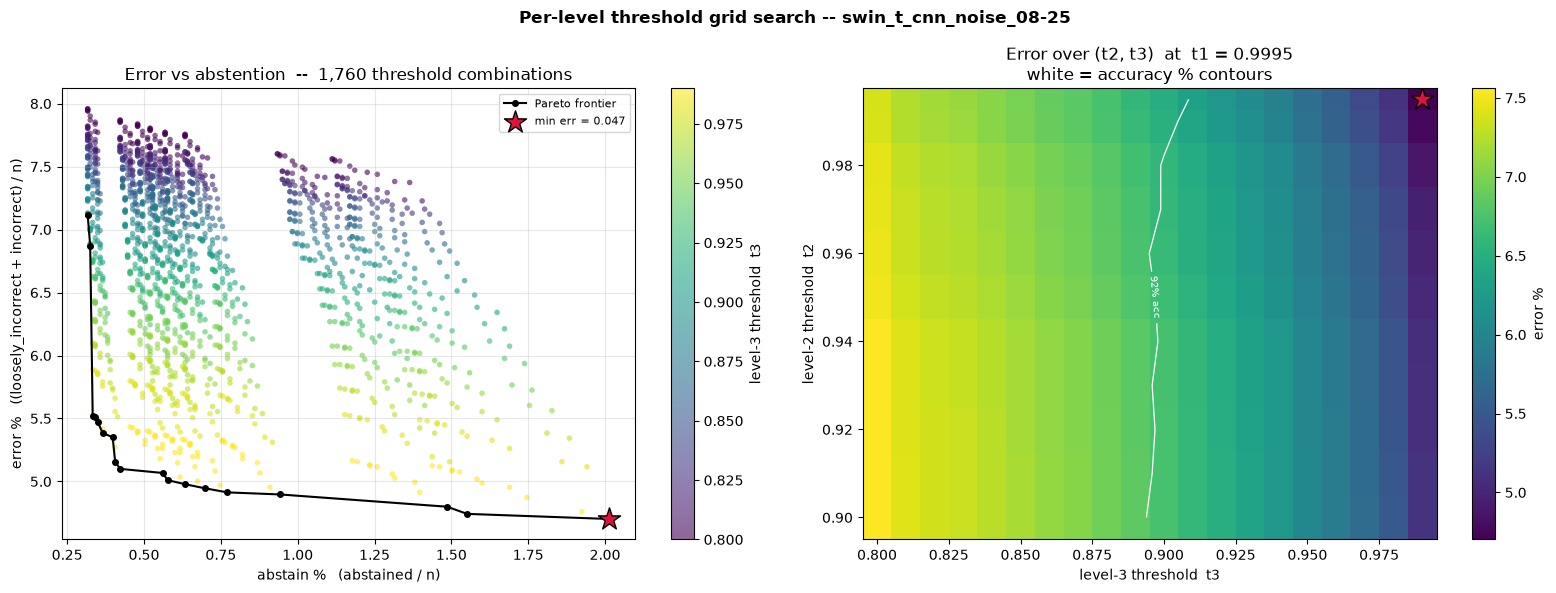

,t1,t2,t3,acc,strict_acc,err,abstain_pct,covered
0,0.9995,0.995,0.99,0.9328,0.7799,0.0470,0.0201,12066
1,0.9990,0.995,0.99,0.9371,0.7803,0.0474,0.0155,12123
2,0.9995,0.990,0.99,0.9332,0.7799,0.0476,0.0192,12077
3,0.9990,0.990,0.99,0.9371,0.7803,0.0480,0.0149,12131
4,0.9995,0.980,0.99,0.9338,0.7799,0.0487,0.0175,12099
5,0.9900,0.995,0.99,0.9416,0.7811,0.0490,0.0094,12198
6,0.9800,0.995,0.99,0.9432,0.7813,0.0491,0.0077,12219
7,0.9990,0.980,0.99,0.9369,0.7803,0.0491,0.0140,12142
8,0.9700,0.995,0.99,0.9436,0.7815,0.0495,0.0070,12228
9,0.9995,0.970,0.99,0.9336,0.7799,0.0495,0.0169,12106


In [ ]:
# Full Cartesian grid over the three per-level thresholds. threshold_grid_search /
# print_grid_search_report / plot_threshold_grid all live in runs/scripts/hiernet_eval.py.
# Every rate (acc / strict_acc / err / abstain_pct) is over ALL n test samples and sums to 1.
T1_GRID = [0.9, 0.95, 0.96, 0.97, 0.98, 0.99, 0.999, 0.9995]
T2_GRID = [0.90, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 0.995]
T3_GRID = list(np.round(np.arange(0.80, 0.995, 0.01), 2))          # 0.80 0.81 082 .. 0.99  (20 values)

grid_df = threshold_grid_search(
    all_paths, all_confidences, all_true_leaves, model.hierarchy, T1_GRID, T2_GRID, T3_GRID)
print(f'Evaluated {len(grid_df):,} combinations  '
      f'({len(T1_GRID)} x {len(T2_GRID)} x {len(T3_GRID)})\n')

print_grid_search_report(grid_df, all_paths, all_confidences, all_true_leaves, model.hierarchy)

fig, frontier, best_combo = plot_threshold_grid(
    grid_df, title=f'Per-level threshold grid search -- {os.path.basename(TRAINING_RESULT_PATH)}')
plt.show()

grid_df.sort_values('err').head(20).reset_index(drop=True).round(
    {'acc': 4, 'strict_acc': 4, 'err': 4, 'abstain_pct': 4})

## Per-level settle distribution

For a chosen threshold vector, how many samples ultimately settle at each level (vs. abstain).

In [13]:
# settle_depth_distribution(thresholds, all_paths, all_confidences, hierarchy) -- from hiernet_eval.
CHOSEN_THRESHOLDS = [0.98, 0.995, 0.99]  # <-- set this to whichever vector you land on above
settle_depth_distribution(CHOSEN_THRESHOLDS, all_paths, all_confidences, model.hierarchy)

abstained      95
level 1       999
level 2      1431
level 3      9789
Name: count, dtype: int64

## Per-class ID outcomes

Stacked bar per **true (manual) class** of where the `CHOSEN_THRESHOLDS` cascade's prediction lands relative to that class -- the manual-ID-vs-AI-ID rubric (`classify_id_outcome` in `runs/scripts/hiernet_eval.py`):

- **Correct_All** -- predicted the true leaf exactly (AI ID == manual ID).
- **Correct_Incomplete** -- backed off to a genuine ancestor of the true leaf: right branch, just coarser than the manual ID.
- **Incorrect_L3** -- agrees with the manual ID at levels 1-2, wrong at level 3 (wrong species, right coarse group).
- **Incorrect_L2** -- agrees at level 1, wrong at level 2 (wrong coarse group, still `Zoop-yes`).
- **Incorrect_All** -- wrong already at level 1 (`Zoop-yes` vs `Zoop-No`): no level agrees.
- **Abstained** -- even the level-1 decision failed its threshold; no prediction made.

Unlike the `## Confidence` breakdown in `hiernet_mnr.ipynb` (which splits the wrong predictions by whether the cascade committed or hedged), this splits them by the level the error entered at. Reuses the cell-above `(all_paths, all_confidences, all_true_leaves)` cache -- the model never re-runs.

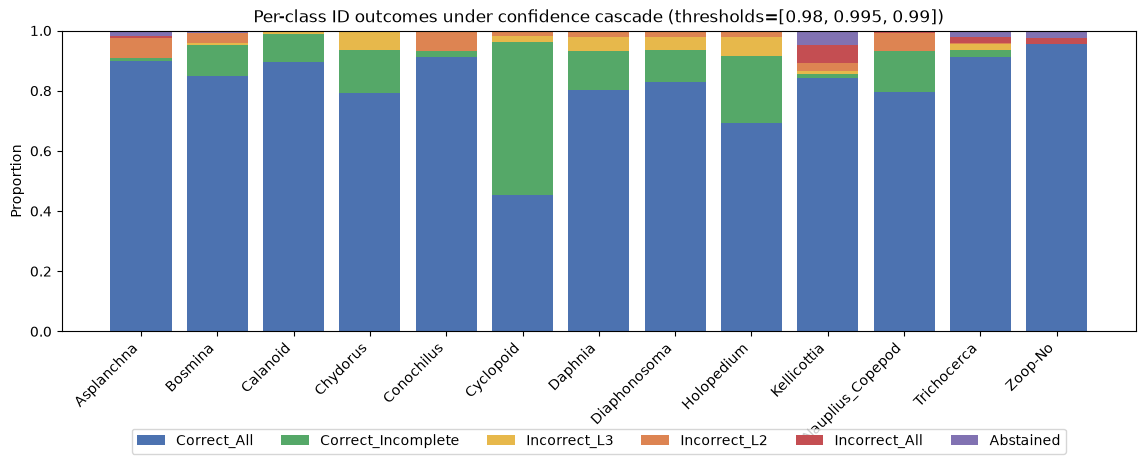

,correct_all,correct_incomplete,incorrect_l3,incorrect_l2,incorrect_all,abstained
Asplanchna,0.899,0.009,0.001,0.066,0.005,0.019
Bosmina,0.848,0.104,0.007,0.033,0.000,0.007
Calanoid,0.895,0.094,0.004,0.006,0.000,0.000
Chydorus,0.792,0.144,0.060,0.005,0.000,0.000
Conochilus,0.912,0.020,0.000,0.063,0.000,0.005
Cyclopoid,0.453,0.507,0.023,0.016,0.000,0.001
Daphnia,0.804,0.129,0.045,0.018,0.000,0.004
Diaphonosoma,0.829,0.107,0.043,0.021,0.000,0.000
Holopedium,0.692,0.222,0.063,0.023,0.000,0.000
Kellicottia,0.843,0.012,0.010,0.027,0.062,0.047


In [14]:
# Per-class manual-ID-vs-AI-ID rubric under the CHOSEN_THRESHOLDS cascade.
# per_class_id_outcomes / plot_id_outcome_stacked_bar live in runs/scripts/hiernet_eval.py;
# passing predictions=... reuses the cache from "Run inference once over the test set" above.
id_to_name = {v: k for k, v in messy_hier_dataset.label_to_ids.items()}

id_outcome_props = per_class_id_outcomes(
    model, messy_loader, CHOSEN_THRESHOLDS, model.hierarchy, id_to_name, device,
    predictions=(all_paths, all_confidences, all_true_leaves),
)

plot_id_outcome_stacked_bar(
    id_outcome_props,
    f'Per-class ID outcomes under confidence cascade (thresholds={CHOSEN_THRESHOLDS})',
)
plt.show()

pd.DataFrame(id_outcome_props).T[list(ID_OUTCOME_KEYS)].round(3)